In [2]:
# 03 — xG Model Training

# Train and compare two xG models on the feature matrix built in 02:
# 1. Logistic regression baseline (the "can I beat the base rate?" check)
# 2. XGBoost (does a nonlinear model do better?)

# Evaluate with log loss, ROC-AUC, and Brier score on a held-out test set,
# inspect calibration, benchmark against StatsBomb's own xG, and save the winner.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, roc_auc_score, brier_score_loss
from sklearn.calibration import calibration_curve

import xgboost as xgb
import joblib

In [3]:
# my data set from 02
dataset = pd.read_csv('../data/xg_dataset.csv')

X = dataset.drop(columns='is_goal')
y = dataset['is_goal']

print("X shape:", X.shape)
print("Features:", X.columns.tolist())
print("Base goal rate:", y.mean().round(3))
X.head()

X shape: (1706, 9)
Features: ['distance', 'angle', 'body_Head', 'body_Left Foot', 'body_Other', 'body_Right Foot', 'type_Free Kick', 'type_Open Play', 'type_Penalty']
Base goal rate: 0.107


,distance,angle,body_Head,body_Left Foot,body_Other,body_Right Foot,type_Free Kick,type_Open Play,type_Penalty
0,31.016125,0.240497,0,0,0,1,0,1,0
1,5.099020,1.325818,0,0,0,1,0,1,0
2,16.643317,0.405354,0,0,0,1,0,1,0
3,30.083218,0.246831,0,0,0,1,0,1,0
4,12.529964,0.557962,0,0,0,1,0,1,0


In [4]:
# split off a test set
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# carve a validation set out of the remainder (used only for XGBoost early stopping)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.2, stratify=y_trainval, random_state=42
)

print(f"train: {len(X_train)}  val: {len(X_val)}  test: {len(X_test)}")
print(f"goal rate  train={y_train.mean():.3f}  val={y_val.mean():.3f}  test={y_test.mean():.3f}")

train: 1091  val: 273  test: 342
goal rate  train=0.107  val=0.106  test=0.108


In [14]:
# name: name of model
# y_true: true y values
# p_pred: probability of goal
def evaluate(name, y_true, p_pred):
    # these are 3 SciKit Learn functions
    ll = log_loss(y_true, p_pred)
    auc = roc_auc_score(y_true, p_pred)
    brier = brier_score_loss(y_true, p_pred)
    print(f"{name:22s} logloss={ll:.4f}  ROC-AUC={auc:.4f}  Brier={brier:.4f}")
    return {"logloss": ll, "roc_auc": auc, "brier": brier}

# Predict Training goal rate for everyone
base_rate = y_train.mean()
_ = evaluate("baseline (base rate)", y_test, np.full(len(y_test), base_rate))

baseline (base rate)   logloss=0.3427  ROC-AUC=0.5000  Brier=0.0965


## Model 1 — Logistic Regression baseline

In [15]:
# This is a pipeline that scales the different features 
# to account for the big range of numbers using the 
# StandardScalar() function, and then the logreg itself w/
# 1000 iterations of of gradient descent
logreg = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000)),
])

# Run pipeline in order, fit scaler on X_train
# fit LogReg classifier on scaled features
logreg.fit(X_train, y_train) 

# predict probability of a goal (y = 1)
p_lr = logreg.predict_proba(X_test)[:, 1]
lr_scores = evaluate("logistic regression", y_test, p_lr)

logistic regression    logloss=0.2393  ROC-AUC=0.8645  Brier=0.0675


### Baseline Logistic Regression interpretation
`logloss = 0.2393` : Measure how close model's pred. prob. is to true label, lower the better, 0.2393 is an improvement on the baseline<br>
`ROC-AUC = 0.8645` : Probability that a rand. chosen goal gets higher xG than rand. chosen non goal, 0.8645 is an improvement on the baseline<br>
`Brier = 0.0675` : Measure accuracy of probabilistic preds., lower the better, also an improvement on baseline model<br>

## Model 2 — XGBoost

In [16]:
# Configure xgBoost model with all these parameters
# that guard against overfitting on a small dataset.
xgb_clf = xgb.XGBClassifier(
    n_estimators=400,          # upper bound; early stopping usually ends far sooner
    max_depth=4,               # shallow trees -> less overfitting on a small dataset
    learning_rate=0.05,
    subsample=0.8,             # each tree sees 80% of rows...
    colsample_bytree=0.8,      # ...and 80% of columns -> regularization
    objective="binary:logistic",
    eval_metric="logloss",
    early_stopping_rounds=30,
    random_state=42,
    n_jobs=-1,
)

# Train model while evaluating against the two validation sets,
# verbose=False means the per-round log output is silenced
xgb_clf.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

# print where log loss bottomed out
print("best iteration:", xgb_clf.best_iteration)

p_xgb = xgb_clf.predict_proba(X_test)[:, 1]
xgb_scores = evaluate("xgboost", y_test, p_xgb)

best iteration: 79
xgboost                logloss=0.2401  ROC-AUC=0.8578  Brier=0.0676


### Baseline Logistic Regression interpretation
The numbers between the XGBoost model and LogReg model are about the same, meaning they performed about the same

## Calibration — do the probabilities mean what they say?

In [17]:
from statsbombpy import sb
import warnings; warnings.filterwarnings('ignore')

matches = sb.matches(competition_id=43, season_id=3)   # same source as notebook 02

raw = []
for mid in matches['match_id']:
    ev = sb.events(match_id=mid)
    raw.append(ev[ev['type'] == 'Shot'])
raw_shots = pd.concat(raw, ignore_index=True)

# ASSUMPTION: same competition/season + ignore_index => identical row order as the CSV.
assert len(raw_shots) == len(dataset), "row count mismatch — order assumption broken!"

sb_xg     = raw_shots['shot_statsbomb_xg'].reset_index(drop=True)
match_ids = raw_shots['match_id'].reset_index(drop=True)

# Line up StatsBomb's xG with our held-out test rows using the test index.
sb_xg_test = sb_xg.loc[X_test.index]

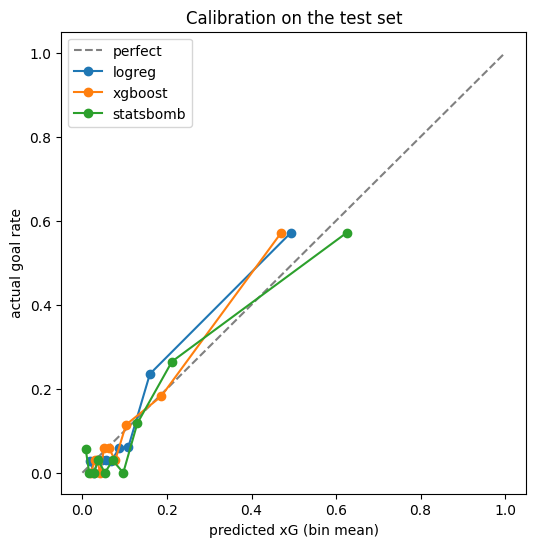

In [18]:
# Calibration Plot
def cal_points(y_true, p, bins=10):
    frac_pos, mean_pred = calibration_curve(y_true, p, n_bins=bins, strategy='quantile')
    return mean_pred, frac_pos

plt.figure(figsize=(6, 6))
plt.plot([0, 1], [0, 1], '--', color='gray', label='perfect')

for label, p in [("logreg", p_lr), ("xgboost", p_xgb), ("statsbomb", sb_xg_test.values)]:
    mp, fp = cal_points(y_test, p)
    plt.plot(mp, fp, marker='o', label=label)

plt.xlabel("predicted xG (bin mean)")
plt.ylabel("actual goal rate")
plt.title("Calibration on the test set")
plt.legend()
plt.show()

## Benchmark — my xG totals vs StatsBomb's, per match

winner: logreg
Total xG  — mine: 185.5  StatsBomb: 203.3
Per-match correlation: 0.984


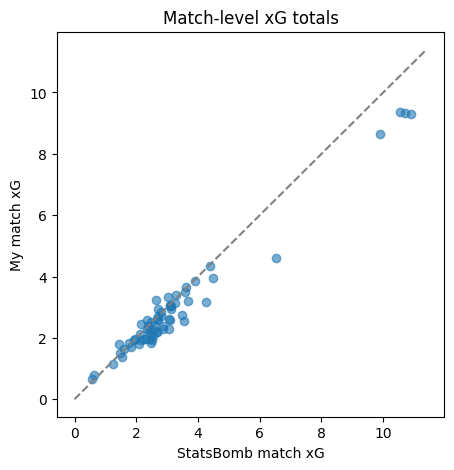

In [19]:
# Pick whichever model won on test log loss.
winner_name, winner = ("xgboost", xgb_clf) if xgb_scores["logloss"] < lr_scores["logloss"] else ("logreg", logreg)
print("winner:", winner_name)

# Predict on ALL shots for the aggregate check (note: includes training shots — this is a
# directional agreement sanity check, not a held-out metric).
p_all = winner.predict_proba(X)[:, 1]

comp = pd.DataFrame({"match_id": match_ids, "my_xg": p_all, "sb_xg": sb_xg})
totals = comp.groupby("match_id")[["my_xg", "sb_xg"]].sum()

print("Total xG  — mine:", round(totals['my_xg'].sum(), 1),
      " StatsBomb:", round(totals['sb_xg'].sum(), 1))
print("Per-match correlation:", round(totals['my_xg'].corr(totals['sb_xg']), 3))

plt.figure(figsize=(5, 5))
plt.scatter(totals['sb_xg'], totals['my_xg'], alpha=0.6)
lims = [0, totals[['my_xg', 'sb_xg']].values.max() + 0.5]
plt.plot(lims, lims, '--', color='gray')
plt.xlabel("StatsBomb match xG"); plt.ylabel("My match xG")
plt.title("Match-level xG totals"); plt.show()

## Save the winning model

In [20]:
import os
os.makedirs('../models', exist_ok=True)

path = f'../models/xg_{winner_name}.joblib'
joblib.dump(winner, path)
print("saved:", path)

# quick reload check — the artifact must work standalone at serve time
reloaded = joblib.load(path)
print("reload sanity xG (first 5):", reloaded.predict_proba(X.head())[:, 1].round(3))

saved: ../models/xg_logreg.joblib
reload sanity xG (first 5): [0.025 0.487 0.092 0.027 0.149]
